In [2]:
import pandas as pd
import numpy as np
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import zscore

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib.pyplot as plt

import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [3]:
# pandas read Excel file and stores it in a dataframe df
df = pd.read_excel("COM6013_-_Data_Mining_[2923]_-_SMART_Banking_data.xlsx", header=1)

# set index 'customer_id'
df = df.set_index('customer_id')

# show 5 first rows of df
# print(df.head())

In [4]:
# print(df.shape)

In [5]:
# print(df.isnull().sum())

In [6]:
# print(df.dtypes)

In [7]:
for col in df.columns:   
    print(f"{col}:{df[col].unique()}")
    print()

credit_score:[619.  68.  52. 699.  85. 645. 822. 376.  51. 684. 528. 497. 476. 549.
 635. 616. 653. 587. 726. 732. 636. 669. 846. 577. 756. 571. 574. 411.
 591. 533. 553. 722. 475.  49.  84. 582. 472. 465. 556. 834.  66. 776.
 829. 637.  55. 698. 585.  nan 655.  61. 656. 725. 511. 614. 742. 687.
  63. 751. 581. 735. 661. 675. 738. 813. 657.  64. 519. 664. 678. 757.
 416. 665. 777. 543.  56. 493. 652.  75. 729. 646. 647.  88. 524. 769.
  73. 515. 773. 814.  71. 413. 623.  67. 622. 785.  65. 479. 685. 538.
 562. 721. 628. 668. 828. 674. 625. 432.  77. 758. 795. 686. 789. 589.
 461. 584. 579. 663. 682. 793. 691. 485. 754. 535. 716. 539.  76. 586.
 631. 717.   8. 683.  74. 615. 667. 484.  48. 578. 512. 597. 778. 514.
 525. 715.  58.  87. 521. 759. 516. 711. 618. 643. 671. 689.  62. 676.
 572. 695. 592. 567. 694. 547. 594. 673. 767. 763. 712. 662. 659. 523.
 772. 545. 634. 739. 771. 681. 544. 696. 766. 727. 693. 557. 531. 498.
 651. 791. 733. 811. 714. 782. 775. 799. 744. 747. 583. 627. 731

In [8]:
## categorical variables
# convert categorical variables to category type
df['country'] = df['country'].astype('category')
df['gender'] = df['gender'].astype('category')

# get dumies for cathegorical variables
df_encoded = pd.get_dummies(df, columns=['country', 'gender'], drop_first=False)
# print(df_encoded.head())

country_France:
country_France
False    1037
True      962
Name: count, dtype: int64

country_Germany:
country_Germany
False    1494
True      505
Name: count, dtype: int64

country_Spain:
country_Spain
False    1467
True      532
Name: count, dtype: int64

gender_Female:
gender_Female
False    1064
True      935
Name: count, dtype: int64

gender_Male:
gender_Male
True     1064
False     935
Name: count, dtype: int64



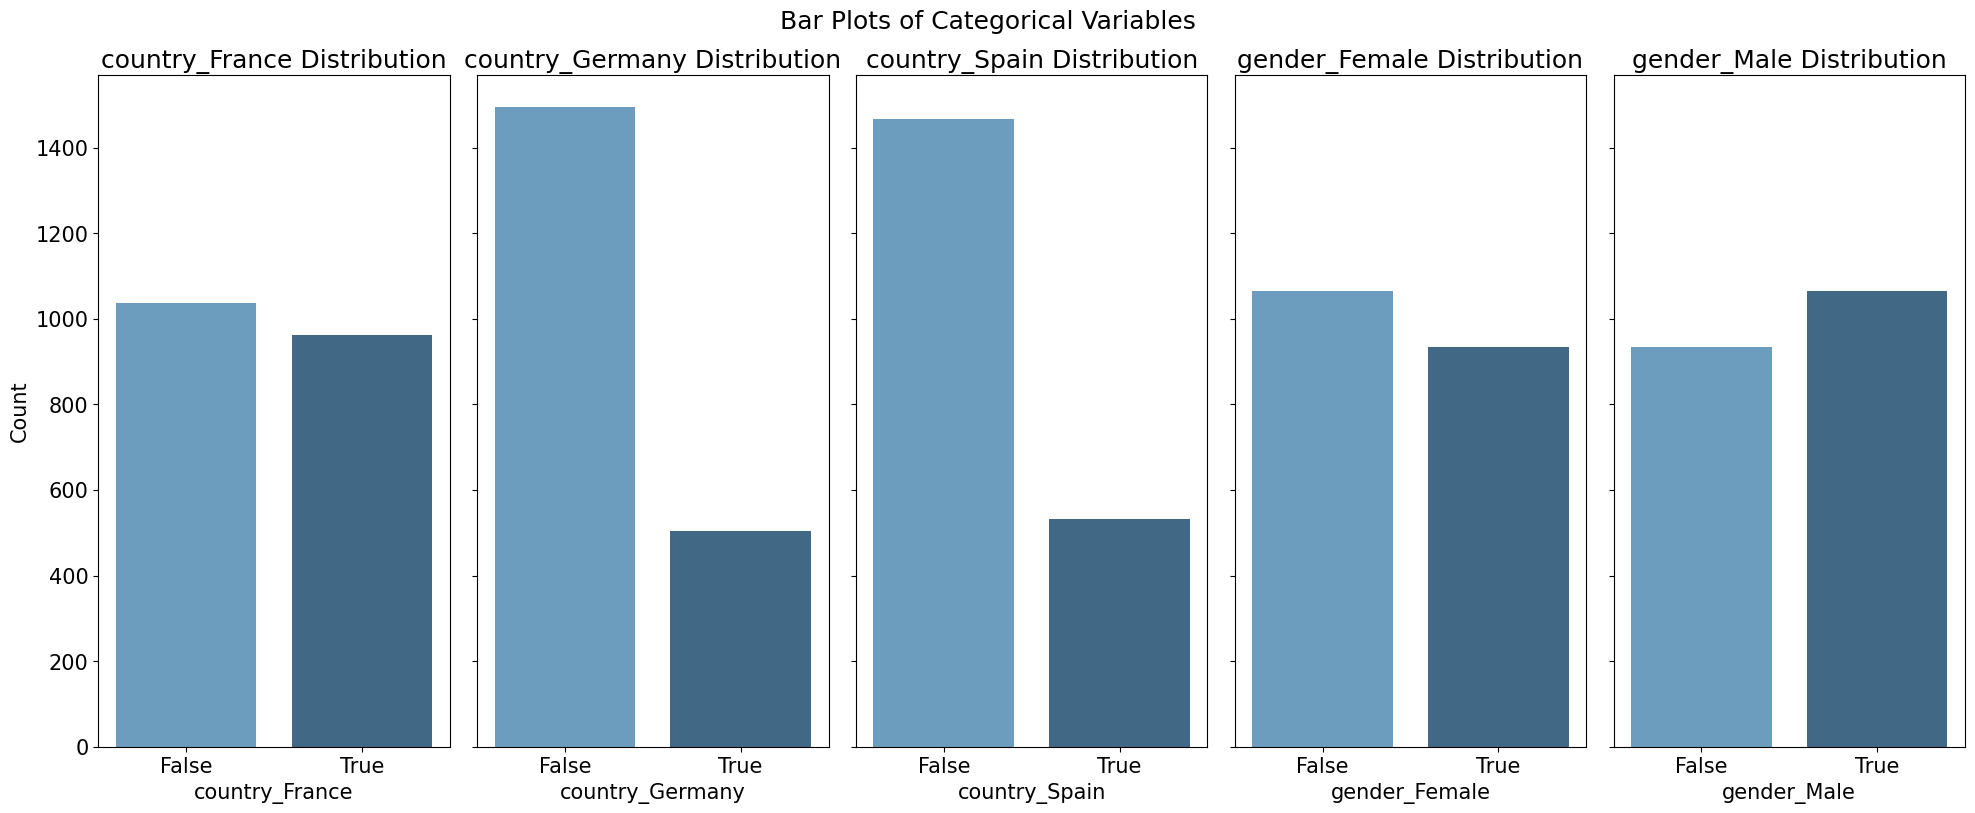

In [9]:

# Frequency counts for categorical variables
categorical_columns = ['country_France', 'country_Germany', 'country_Spain', 'gender_Female', 'gender_Male']

for col in categorical_columns:
    print(f"{col}:\n{df_encoded[col].value_counts()}\n")
    
    
# Set global font size for consistency
plt.rcParams.update({'font.size': 15})

# Set up a grid of subplots
fig, axes = plt.subplots(1, len(categorical_columns), figsize=(20, 8), sharey=True)  

# Plot each categorical column
for i, col in enumerate(categorical_columns):
    sns.countplot(x=col, data=df_encoded, ax=axes[i], palette='Blues_d')
    axes[i].set_title(f'{col} Distribution')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count' if i == 0 else '')  

# Adjust layout
plt.tight_layout()
plt.suptitle('Bar Plots of Categorical Variables', y=1.02)

plt.show()

In [10]:
# numerical variables

In [11]:
# numerical variables
# fillna 
df_encoded['credit_score'].fillna(df_encoded['credit_score'].mean(), inplace=True)
df_encoded['age'].fillna(df_encoded['age'].median(), inplace=True)
df_encoded['tenure'].fillna(df_encoded['tenure'].median(), inplace=True)

In [12]:
df_balance_0 = df_encoded.copy()
df_balance_0['balance'].fillna(0, inplace=True)

df_mean = df_encoded.copy()
df_mean['balance'].fillna(df_mean['balance'].mean(), inplace=True)

df_median = df_encoded.copy()
df_median['balance'].fillna(df_median['balance'].median(), inplace=True)

In [13]:

# save original index
original_index = df_encoded.index

# Select relevant columns for imputer
columns_for_imputation = df_encoded.columns

# create iterative imputer
imputer = IterativeImputer(max_iter=10, random_state=42)

# apply imputer (without index)
data_imputed = imputer.fit_transform(df_encoded)

# convert imputed data in a new df keeping original columns
df_imputed = pd.DataFrame(data_imputed, columns=columns_for_imputation, index=original_index)


In [14]:

# Save the original index
original_index = df_encoded.index

# Select columns for imputation
columns_to_impute = df_encoded.columns

# Create the KNN imputer
imputer = KNNImputer(n_neighbors=1)

# Apply the KNN imputer (index is not included in the transformation)
data_imputed_knn = imputer.fit_transform(df_encoded)

# Convert the result to a new DataFrame, preserving columns and index
df_imputed_knn = pd.DataFrame(data_imputed_knn, columns=columns_to_impute, index=original_index)


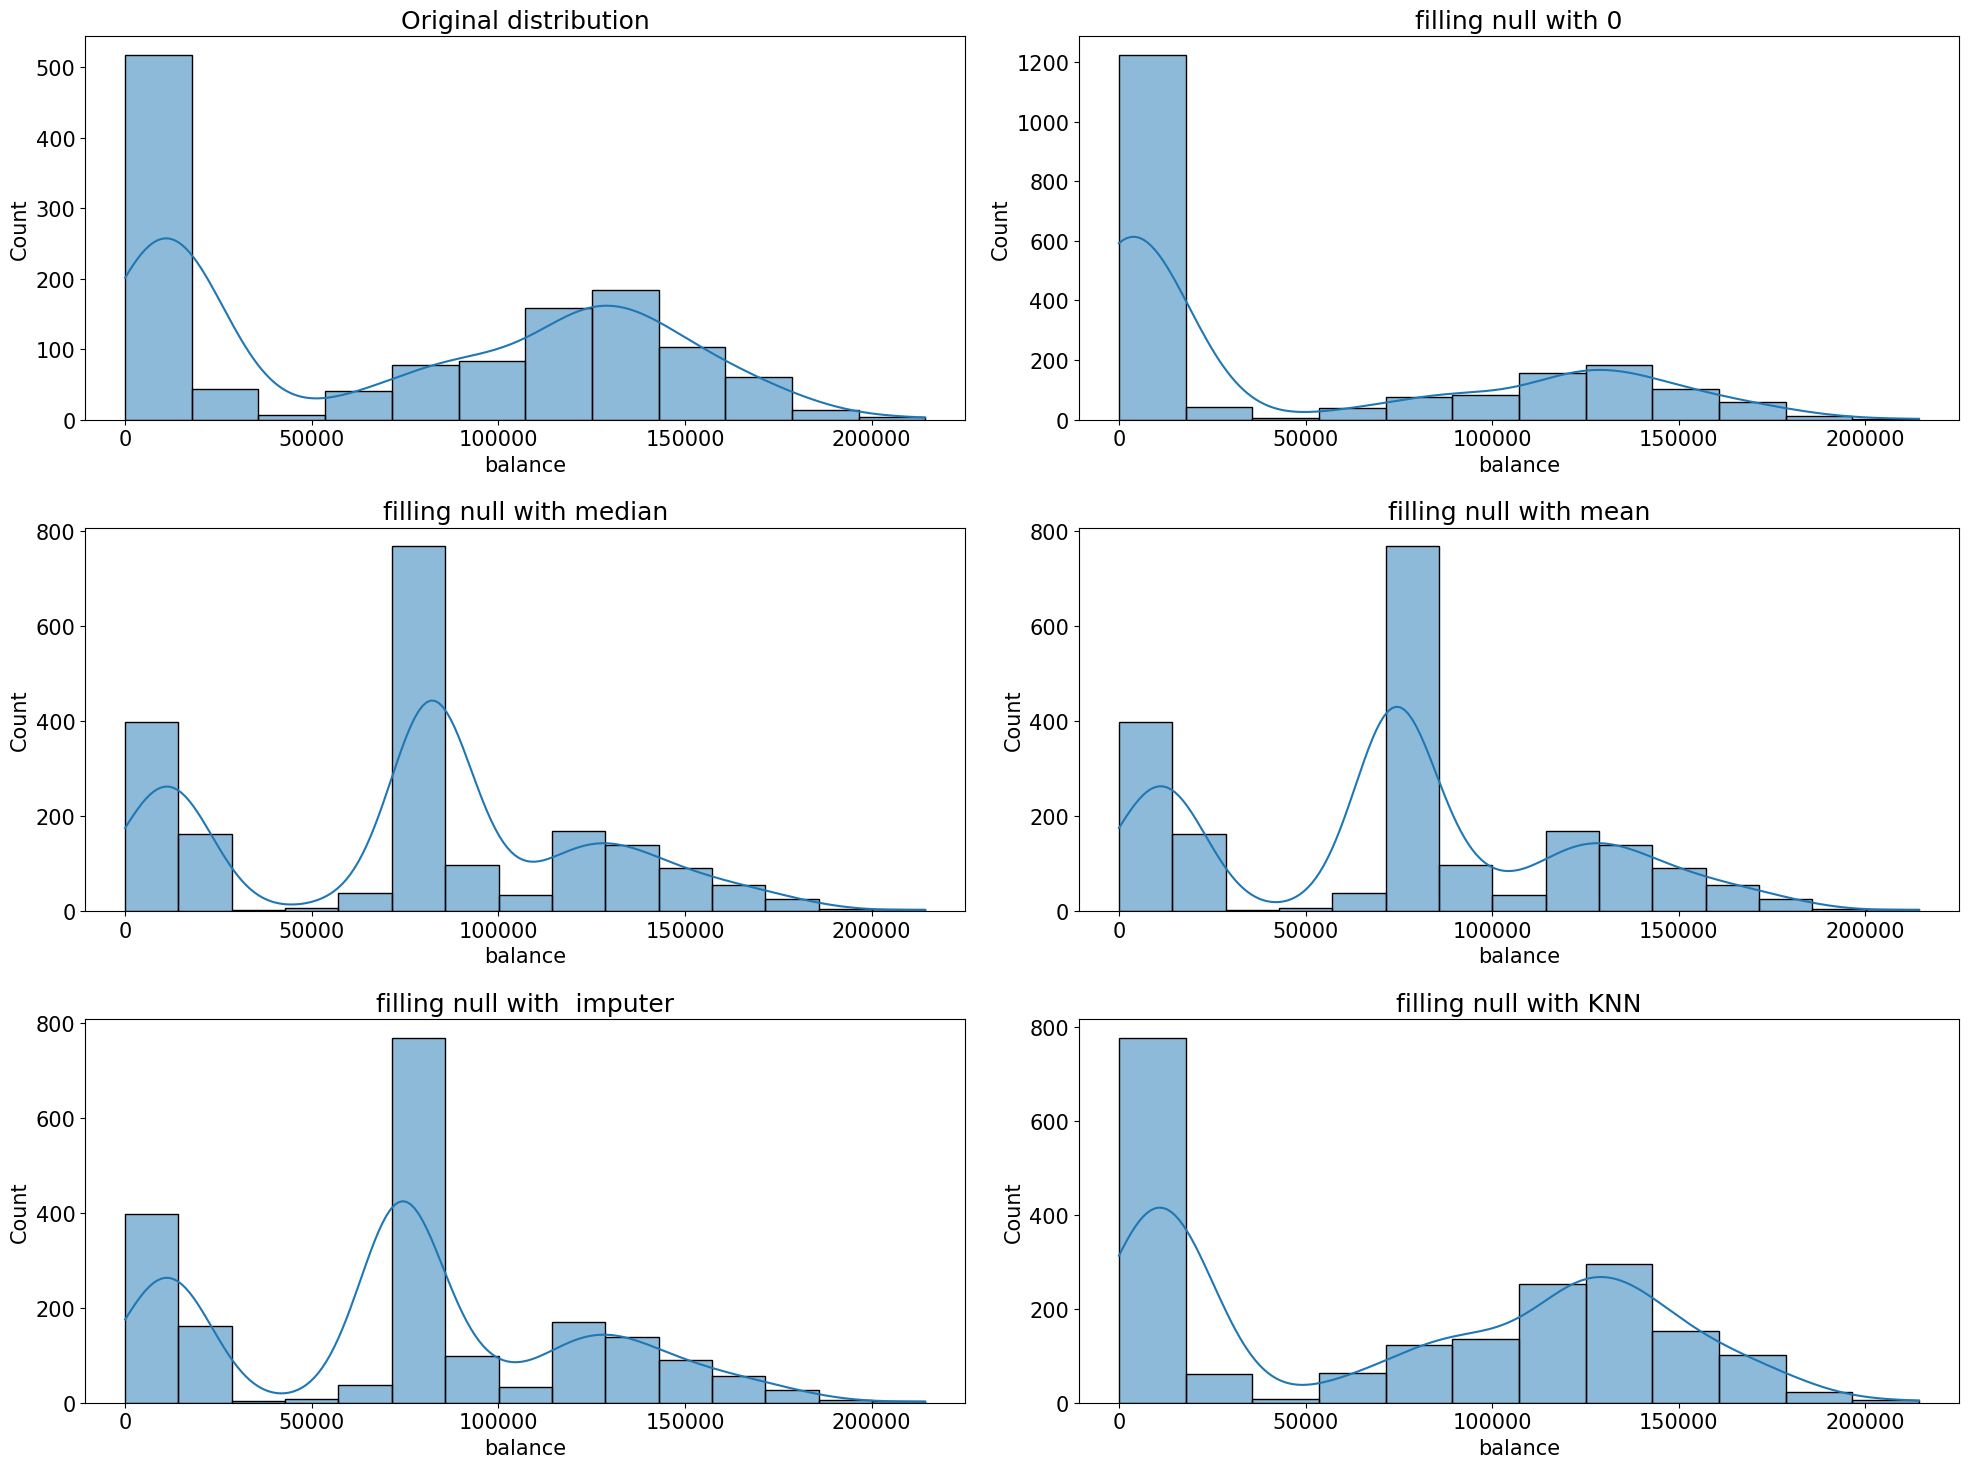

In [15]:

# Crear la figura con subplots
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(20, 15))

# Crear los histogramas
sns.histplot(df['balance'], ax=axes[0][0], kde=True)
axes[0][0].set_title('Original distribution')

sns.histplot(df_balance_0['balance'], ax=axes[0][1], kde=True)
axes[0][1].set_title('filling null with 0')

sns.histplot(df_median['balance'], ax=axes[1][0], kde=True)
axes[1][0].set_title('filling null with median')

sns.histplot(df_mean['balance'], ax=axes[1][1], kde=True)
axes[1][1].set_title('filling null with mean')

sns.histplot(df_imputed['balance'], ax=axes[2][0], kde=True)
axes[2][0].set_title('filling null with  imputer')

sns.histplot(df_imputed_knn['balance'], ax=axes[2][1], kde=True)
axes[2][1].set_title('filling null with KNN')

plt.rcParams.update({'font.size': 17})


# Ajustar la visualización
plt.tight_layout()
plt.show()

In [16]:
# List of numeric columns
numeric_columns = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary']

In [17]:
print(df_imputed_knn[numeric_columns].describe())

       credit_score          age       tenure        balance  estimated_salary
count   1999.000000  1999.000000  1999.000000    1999.000000       1999.000000
mean     527.806338    35.510755     4.865433   75669.811376      67231.244112
std      246.634703    14.050451     2.602340   60218.887731      64825.479022
min        5.000000     2.000000     1.000000      19.500000          6.360000
25%      490.500000    29.000000     3.000000   12911.970000       9984.935000
50%      618.000000    36.000000     5.000000   84745.300000      44244.490000
75%      694.000000    43.000000     7.000000  129678.410000     125301.780000
max      849.000000    82.000000     9.000000  214346.960000     199857.470000


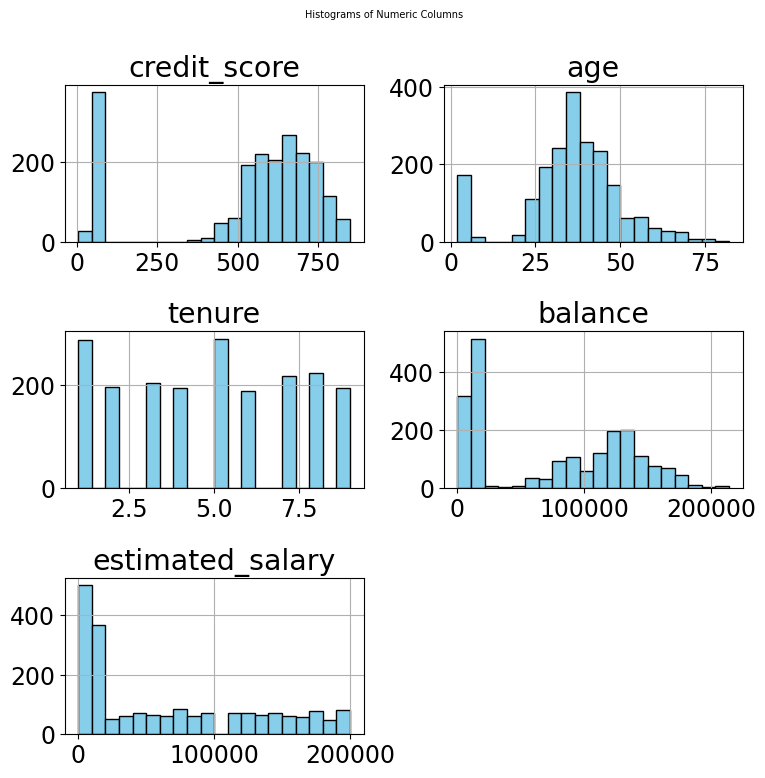

In [18]:
# Plot histograms
df_imputed_knn[numeric_columns].hist(figsize=(8, 8), bins=20, color='skyblue', edgecolor='black')
plt.suptitle('Histograms of Numeric Columns', fontsize=7)
plt.tight_layout()
plt.show()

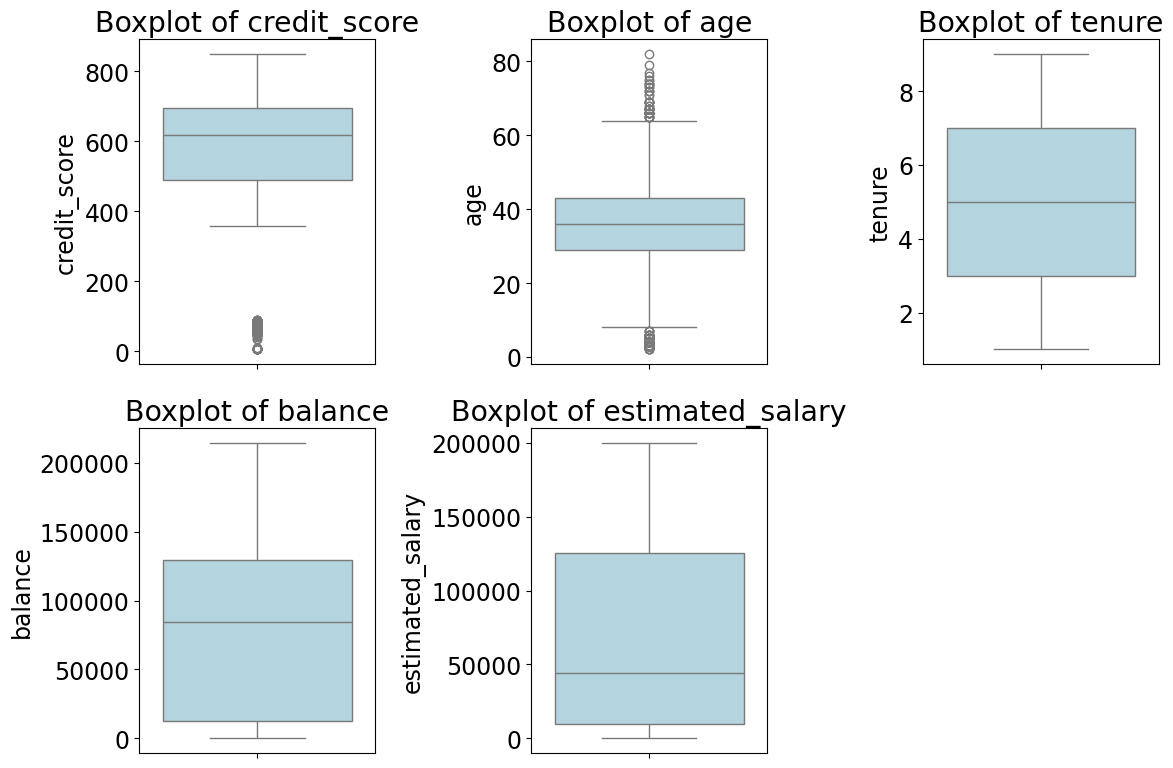

In [19]:
# Create boxplots for numeric columns
plt.figure(figsize=(12, 8))
for i, col in enumerate(numeric_columns, 1):
    plt.subplot(2, 3, i)  # Adjust rows/cols as needed
    sns.boxplot(y=df_imputed_knn[col], color='lightblue')
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

In [20]:


# Function to detect outliers using IQR and Z-Score
def detect_outliers(df, numeric_columns, z_threshold=3):
    results = {'Column': [], 'IQR Outliers': [], 'Z-Score Outliers': []}
    
    for col in numeric_columns:
        # IQR Method
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        iqr_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
        
        # Z-Score Method
        z_scores = zscore(df[col])
        zscore_outliers = (abs(z_scores) > z_threshold).sum()
        
        # add results
        results['Column'].append(col)
        results['IQR Outliers'].append(iqr_outliers)
        results['Z-Score Outliers'].append(zscore_outliers)
    
    # Convert results in a DataFrame
    outlier_summary = pd.DataFrame(results)
    return outlier_summary

# apply function to numeric columns
# numeric_columns = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary']
outliers_summary = detect_outliers(df_imputed_knn, numeric_columns)

# Mostrar los resultados
print(outliers_summary)


             Column  IQR Outliers  Z-Score Outliers
0      credit_score           401                 0
1               age           233                 2
2            tenure             0                 0
3           balance             0                 0
4  estimated_salary             0                 0


In [21]:
print((df_imputed_knn['credit_score'] < 100).sum())
print((df_imputed_knn['age'] <= 18).sum())

401
189


In [22]:
print(df_imputed_knn.shape)

# filter age 
df_imputed_knn = df_imputed_knn[df_imputed_knn['age'] >= 18]

#varify result
print(df_imputed_knn.shape)  

(1999, 10)
(1813, 10)


In [23]:

# Select numeric features for scaling
scaler = MinMaxScaler()

# Apply MinMaxScaler
df_imputed_knn[numeric_columns] = scaler.fit_transform(df_imputed_knn[numeric_columns])


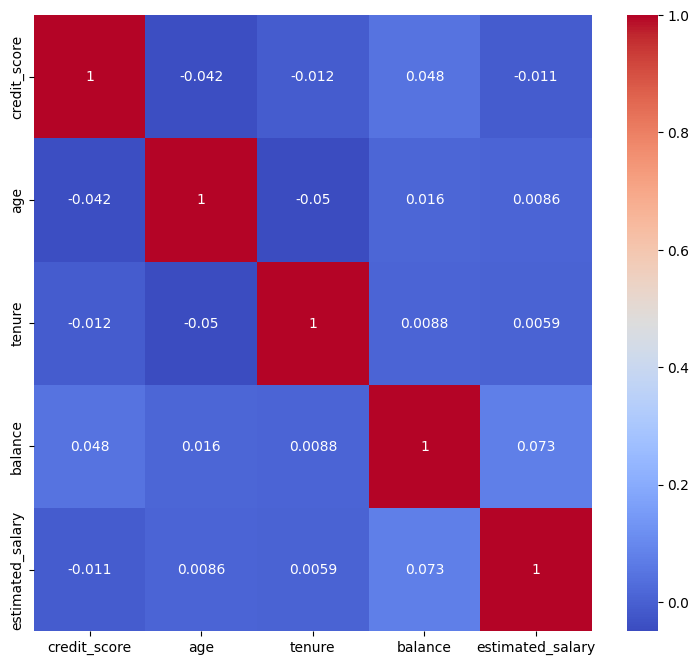

In [24]:

# correlation matrix
corr_matrix = df_imputed_knn[numeric_columns].corr()

# visualize corr heatmap
plt.figure(figsize=(9, 8))  
plt.rcdefaults()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

       credit_score          age       tenure      balance  estimated_salary  \
count   1813.000000  1813.000000  1813.000000  1813.000000       1813.000000   
mean       0.619209     0.324419     0.481040     0.348571          0.338396   
std        0.292190     0.159227     0.326696     0.281151          0.325139   
min        0.000000     0.000000     0.000000     0.000000          0.000000   
25%        0.579384     0.218750     0.250000     0.059759          0.056181   
50%        0.725118     0.296875     0.500000     0.387787          0.226444   
75%        0.816351     0.406250     0.750000     0.604122          0.627341   
max        1.000000     1.000000     1.000000     1.000000          1.000000   

       country_France  country_Germany  country_Spain  gender_Female  \
count     1813.000000      1813.000000    1813.000000    1813.000000   
mean         0.480419         0.247104       0.272477       0.468836   
std          0.499754         0.431447       0.445357       0.4

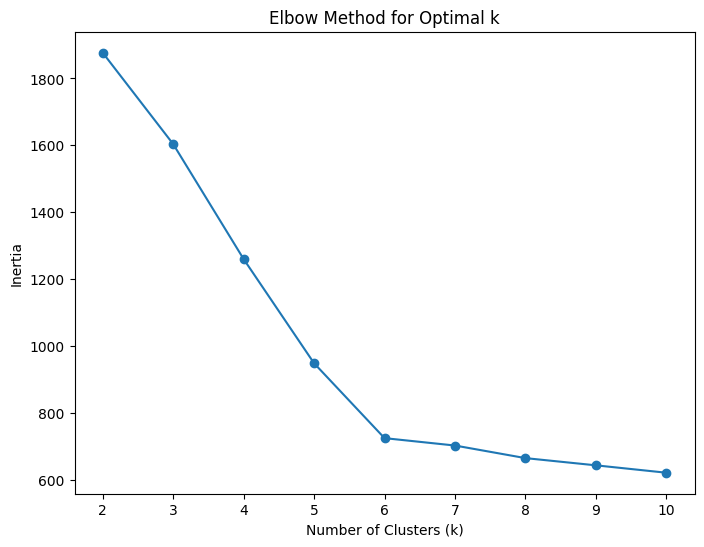

In [25]:

# Find optimal number of clusters using the Elbow Method
inertia = []
k_values = range(2, 11)
print(df_imputed_knn.describe())

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_imputed_knn)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 6))
plt.plot(k_values, inertia, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.show()

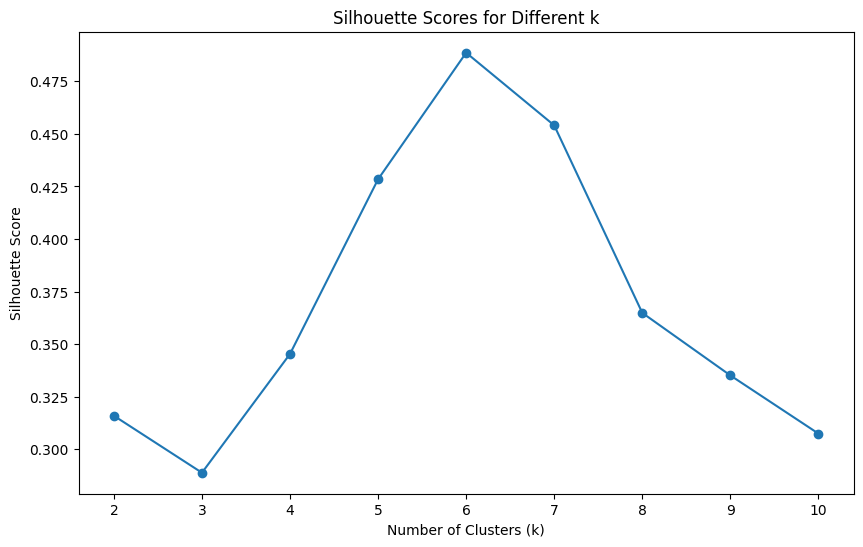

In [26]:
silhouette_scores = []

for k in range(2, 11):  
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df_imputed_knn)
    silhouette_scores.append(silhouette_score(df_imputed_knn, labels))

# Plot Silhouette Scores
plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Scores for Different k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.show()


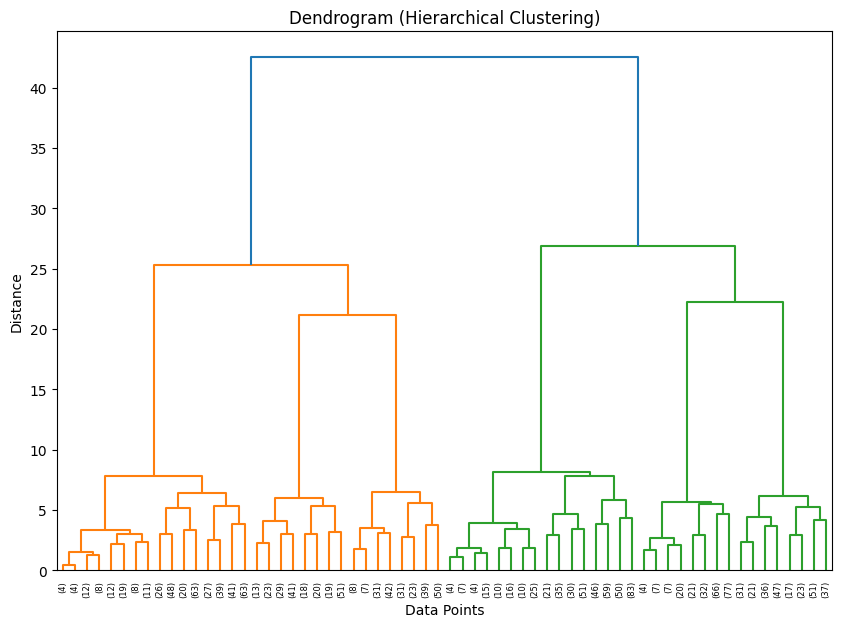

In [27]:
# Hierarchical Clustering


# create dendrograma
linked = linkage(df_imputed_knn, method='ward')  # it could be used method 'average' o 'complete'
# Asign cluster based on distancia
df_imputed_knn['cluster_hierarchical'] = fcluster(linked, t=6, criterion='distance')  

plt.figure(figsize=(10, 7))
dendrogram(linked, truncate_mode='level', p=5)  
plt.title('Dendrogram (Hierarchical Clustering)')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()


cluster_DBSCAN
4    466
0    405
2    263
5    234
1    231
3    214
Name: count, dtype: int64
Proporción de puntos clasificados como ruido: 0.00%


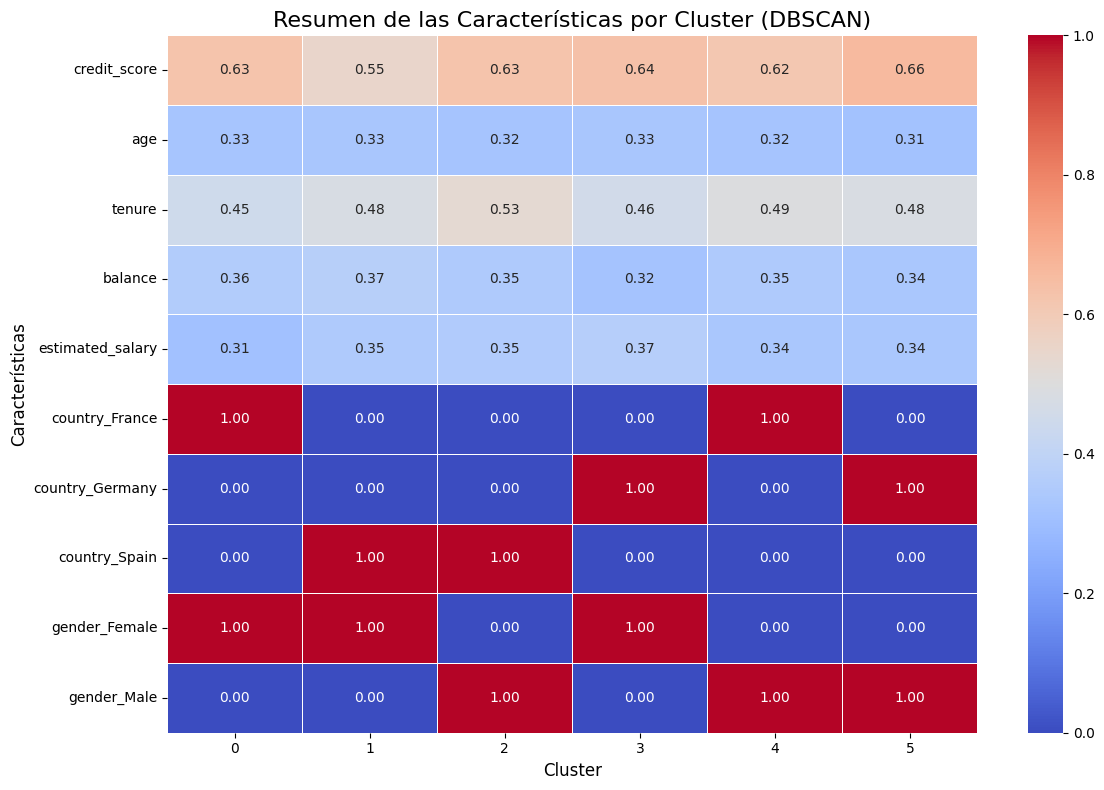

In [28]:


# DBSCAN
dbscan = DBSCAN(eps=1.1, min_samples=5)  # eps y min_samples adjusted
clusters = dbscan.fit_predict(df_imputed_knn)

# add clusters to dataframe
df_imputed_knn['cluster_DBSCAN'] = clusters

# qantity of people in each cluster
print(df_imputed_knn['cluster_DBSCAN'].value_counts())

# % of noise (cluster -1)
noise_ratio = (df_imputed_knn['cluster_DBSCAN'] == -1).sum() / len(df_imputed_knn)
print(f"Proporción de puntos clasificados como ruido: {noise_ratio:.2%}")

# filter valid clusters (excluding noise, cluster -1)
valid_clusters = df_imputed_knn[df_imputed_knn['cluster_DBSCAN'] != -1]

# Agrupar por cluster y calcular el promedio de las características
features = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary', 
            'country_France', 'country_Germany', 'country_Spain', 'gender_Female', 'gender_Male']

cluster_summary_DBSCAN = valid_clusters.groupby('cluster_DBSCAN')[features].mean()

# heatmap 
plt.figure(figsize=(12, 8))
sns.heatmap(cluster_summary_DBSCAN.T, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Resumen de las Características por Cluster (DBSCAN)', fontsize=16)
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Características', fontsize=12)
plt.tight_layout()
plt.show()






<class 'pandas.core.frame.DataFrame'>
Index: 1813 entries, 1563462 to 15779497
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   credit_score          1813 non-null   float64
 1   age                   1813 non-null   float64
 2   tenure                1813 non-null   float64
 3   balance               1813 non-null   float64
 4   estimated_salary      1813 non-null   float64
 5   country_France        1813 non-null   float64
 6   country_Germany       1813 non-null   float64
 7   country_Spain         1813 non-null   float64
 8   gender_Female         1813 non-null   float64
 9   gender_Male           1813 non-null   float64
 10  cluster_hierarchical  1813 non-null   int32  
 11  cluster_DBSCAN        1813 non-null   int64  
dtypes: float64(10), int32(1), int64(1)
memory usage: 177.1 KB
None
cluster
1    466
3    405
2    263
5    234
0    231
4    214
Name: count, dtype: int64


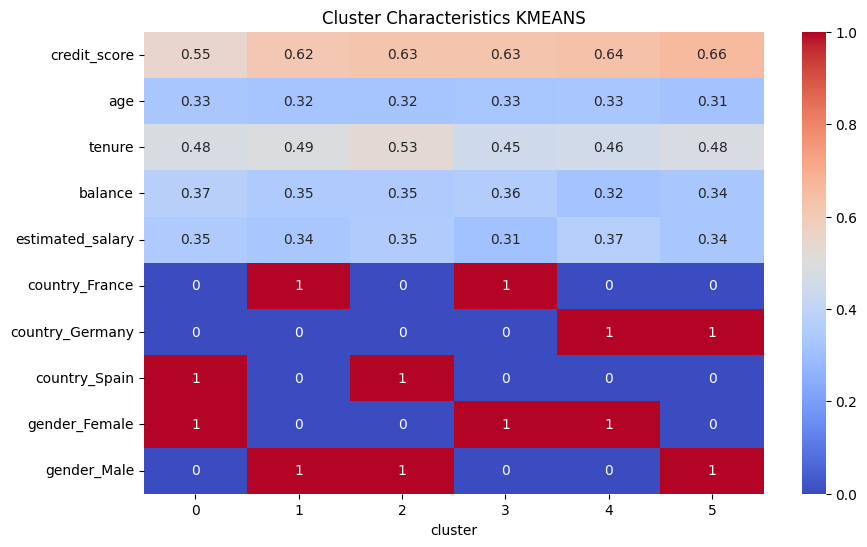

In [29]:
# Assuming optimal k is 6 (the Elbow Method)
print(df_imputed_knn.info())

kmeans = KMeans(n_clusters=6, random_state=42)
df_imputed_knn['cluster'] = kmeans.fit_predict(df_imputed_knn)

# View the cluster assignments
print(df_imputed_knn['cluster'].value_counts())

# Analyse cluster characteristics
cluster_summary = df_imputed_knn.groupby('cluster')[features].mean()

# Plot a heatmap of cluster characteristics
plt.figure(figsize=(10, 6))
sns.heatmap(cluster_summary.T, annot=True, cmap='coolwarm')
plt.title('Cluster Characteristics KMEANS')
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

print(df_imputed_knn.info())

# Hierarchical Clustering
sil_hierarchical = silhouette_score(df_imputed_knn, df_imputed_knn['cluster_hierarchical'])

# DBSCAN
sil_dbscan = silhouette_score(df_imputed_knn, df_imputed_knn['cluster_DBSCAN'])

# K-Means
sil_kmeans = silhouette_score(df_imputed_knn, df_imputed_knn['cluster'])

print(f'Silhouette Score (Hierarchical): {sil_hierarchical:.2f}')
print(f'Silhouette Score (DBSCAN): {sil_dbscan:.2f}')
print(f'Silhouette Score (K-Means): {sil_kmeans:.2f}')



Silhouette Score (Hierarchical): 0.56
Silhouette Score (DBSCAN): 0.73
Silhouette Score (K-Means): 0.73
